# Credit Scoring Model
### CodeAlpha Machine Learning Internship — Task 1

**Objective:** Predict whether a borrower will experience serious financial delinquency in the next two years, using historical financial data (income, debt, credit history).

**Dataset:** [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit) — 150,000 borrowers, 10 financial features.

**Approach:** Logistic Regression and Random Forest classifiers, evaluated with Precision, Recall, F1-Score, and ROC-AUC.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_score, recall_score, f1_score
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## 1. Load the data

In [3]:
df = pd.read_csv(r"C:\Users\User\Downloads\cs-training.csv", index_col=0)
print("Shape:", df.shape)
df.head()


Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 2. Explore the data

 checking for missing values .

In [4]:
df.isnull().sum()


SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [5]:
df["SeriousDlqin2yrs"].value_counts(normalize=True).rename("proportion")


SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64

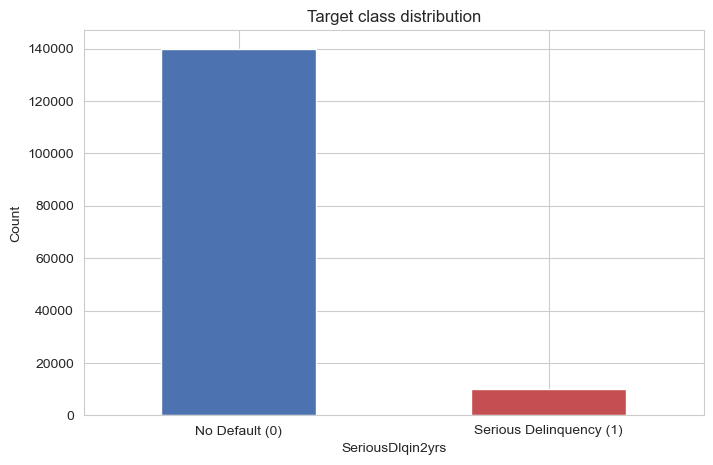

In [6]:
fig, ax = plt.subplots()
df["SeriousDlqin2yrs"].value_counts().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["No Default (0)", "Serious Delinquency (1)"], rotation=0)
ax.set_title("Target class distribution")
ax.set_ylabel("Count")
plt.show()


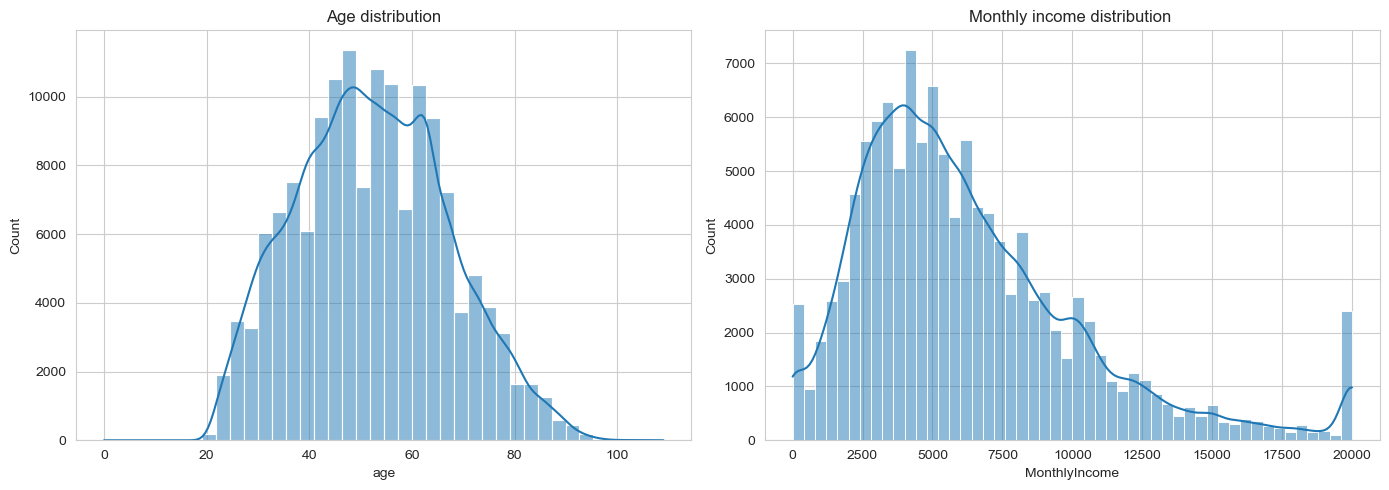

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["age"], bins=40, ax=axes[0], kde=True)
axes[0].set_title("Age distribution")

sns.histplot(df["MonthlyIncome"].dropna().clip(upper=20000), bins=50, ax=axes[1], kde=True)
axes[1].set_title("Monthly income distribution ")
plt.tight_layout()
plt.show()


# 3.Cleaning the data

In [11]:
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())
df["NumberOfDependents"] = df["NumberOfDependents"].fillna(df["NumberOfDependents"].median())

past_due_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
for col in past_due_cols:
    n_anomalous = (df[col] >= 96).sum()
    print(f"{col}: {n_anomalous} anomalous rows capped")
    df[col] = df[col].clip(upper=18)  


NumberOfTime30-59DaysPastDueNotWorse: 0 anomalous rows capped
NumberOfTime60-89DaysPastDueNotWorse: 0 anomalous rows capped
NumberOfTimes90DaysLate: 0 anomalous rows capped




- **DebtToIncome** — actual debt load  (DebtRatio × MonthlyIncome)
- **IncomePerDependent** — income stretched across the household
- **TotalPastDue** — a single  measure of payment delinquency across all three time windows

In [12]:
df["DebtToIncome"] = df["DebtRatio"] * df["MonthlyIncome"]
df["IncomePerDependent"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)
df["TotalPastDue"] = df[past_due_cols].sum(axis=1)

df[["DebtToIncome", "IncomePerDependent", "TotalPastDue"]].describe()


,DebtToIncome,IncomePerDependent,TotalPastDue
count,1.500000e+05,1.500000e+05,150000.000000
mean,1.792761e+06,4.589119e+03,0.497193
std,1.082977e+07,7.974493e+03,2.520975
min,0.000000e+00,0.000000e+00,0.000000
25%,7.768811e+02,2.151000e+03,0.000000
50%,2.107580e+03,4.000000e+03,0.000000
75%,4.803392e+03,5.400000e+03,0.000000
max,1.780186e+09,1.794060e+06,54.000000


## 5. Train / test split

In [13]:
X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (120000, 13)  Test: (30000, 13)


## 6. Model 1 — Logistic Regression



In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_reg.fit(X_train_scaled, y_train)

lr_pred = log_reg.predict(X_test_scaled)
lr_proba = log_reg.predict_proba(X_test_scaled)[:, 1]


## 7. Model 2 — Random Forest



In [15]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight="balanced",
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]


## 8. Evaluate both models

Comparing Precision, Recall, F1, and ROC-AUC side by side.

In [16]:
results = pd.DataFrame({
    "Logistic Regression": [
        precision_score(y_test, lr_pred),
        recall_score(y_test, lr_pred),
        f1_score(y_test, lr_pred),
        roc_auc_score(y_test, lr_proba),
    ],
    "Random Forest": [
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred),
        roc_auc_score(y_test, rf_proba),
    ],
}, index=["Precision", "Recall", "F1-Score", "ROC-AUC"])

results.round(3)


,Logistic Regression,Random Forest
Precision,0.261,0.249
Recall,0.631,0.725
F1-Score,0.369,0.371
ROC-AUC,0.824,0.865


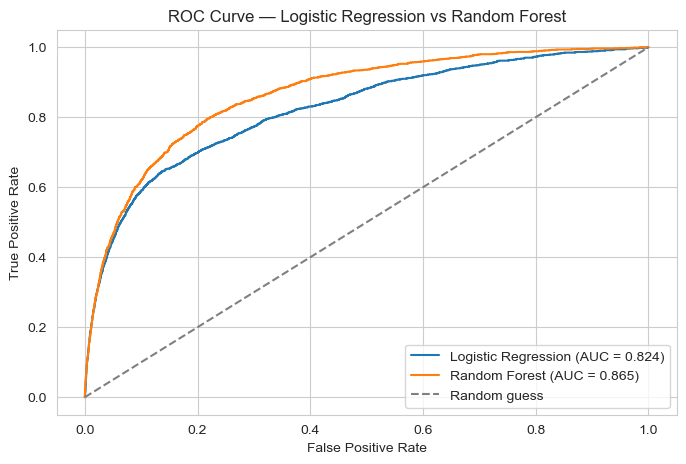

In [17]:
fig, ax = plt.subplots()
for name, proba in [("Logistic Regression", lr_proba), ("Random Forest", rf_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Logistic Regression vs Random Forest")
ax.legend()
plt.show()


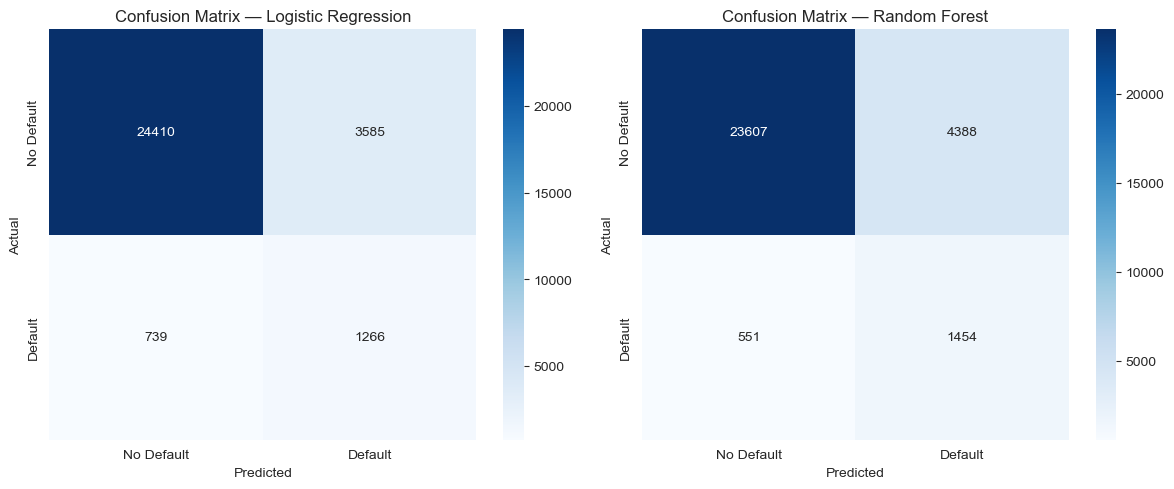

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Logistic Regression", lr_pred), ("Random Forest", rf_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Default", "Default"], yticklabels=["No Default", "Default"])
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


## 9. Which features actually drive the model's predictions?

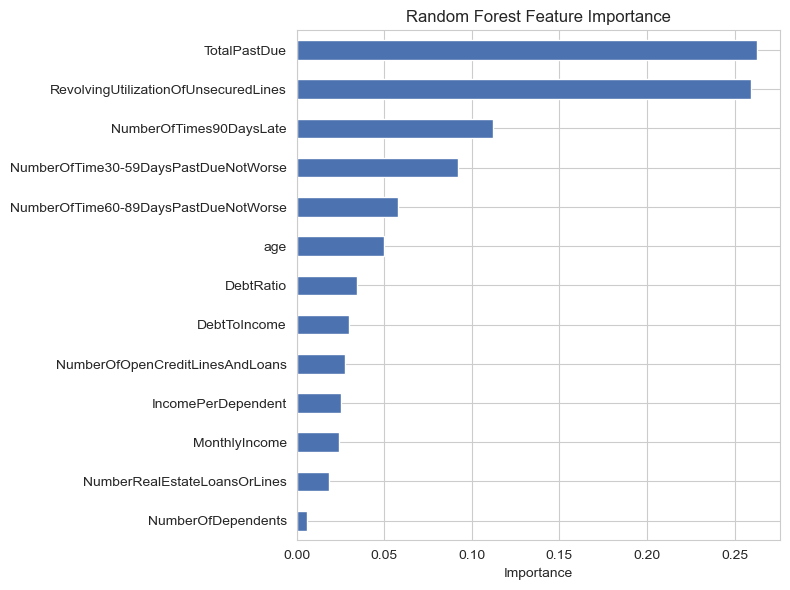

TotalPastDue                            0.262797
RevolvingUtilizationOfUnsecuredLines    0.259667
NumberOfTimes90DaysLate                 0.111910
NumberOfTime30-59DaysPastDueNotWorse    0.092077
NumberOfTime60-89DaysPastDueNotWorse    0.057669
age                                     0.050047
DebtRatio                               0.034254
DebtToIncome                            0.029787
NumberOfOpenCreditLinesAndLoans         0.027903
IncomePerDependent                      0.025285
MonthlyIncome                           0.024031
NumberRealEstateLoansOrLines            0.018757
NumberOfDependents                      0.005817
dtype: float64

In [19]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind="barh", ax=ax, color="#4C72B0")
ax.invert_yaxis()
ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

importances


## 10. Conclusion

- **Random Forest outperforms Logistic Regression** on ROC-AUC and F1-Score,
  **likely because it captures non-linear interactions between features (e.g. how debt ratio and income interact) that a linear model can't.
- The most important predictors are the **revolving credit utilization ratio** and **past-due payment history** 
- **Recall vs. Precision trade-off:** for a real credit scoring system, missing an actual defaulter 
 **(false negative) is usually costlier than wrongly flagging a safe borrower (false positive), 
 **so a lender might tune the classification threshold to favor Recall over Precision.

